In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))
print("Environment ready!")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Environment ready!


In [6]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os

zip_path = "/content/drive/MyDrive/Groundnut_Project/Groundnut_Leaf_dataset.zip"

if os.path.exists(zip_path):
    size_mb = os.path.getsize(zip_path) / (1024 * 1024)
    print("✅ Dataset found!")
    print(f"File size: {size_mb:.2f} MB")
else:
    print("❌ Dataset not found.")
    print("Files in MyDrive:")
    print(os.listdir("/content/drive/MyDrive"))

✅ Dataset found!
File size: 111.61 MB


In [8]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Groundnut_Project/Groundnut_Leaf_dataset.zip"
extract_path = "/content/groundnut_dataset"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")
print("Dataset location:", extract_path)

✅ Dataset extracted successfully!
Dataset location: /content/groundnut_dataset


In [9]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level < 2:
            for file in files[:5]:
                print("  " * (level + 1) + file)

groundnut_dataset/
  Groundnut_Leaf_dataset/
    test/
    train/


In [10]:
import os

dataset_path = "/content/groundnut_dataset/Groundnut_Leaf_dataset"

for split in ["train", "test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"\n{'='*35}")
    print(f"{split.upper()} DATASET")
    print(f"{'='*35}")

    if not os.path.isdir(split_path):
        print("Folder not found:", split_path)
        continue

    for class_name in sorted(os.listdir(split_path)):
        class_path = os.path.join(split_path, class_name)

        if os.path.isdir(class_path):
            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith(
                    (".jpg", ".jpeg", ".png", ".bmp", ".webp")
                )
            ]
            print(f"{class_name}: {len(images)} images")


TRAIN DATASET
early_leaf_spot_1: 1322 images
early_rust_1: 1065 images
healthy_leaf_1: 1462 images
late_leaf_spot_1: 1491 images
nutrition_deficiency_1: 1255 images
rust_1: 1315 images

TEST DATASET
early_leaf_spot_1: 409 images
early_rust_1: 409 images
healthy_leaf_1: 409 images
late_leaf_spot_1: 405 images
nutrition_deficiency_1: 410 images
rust_1: 409 images


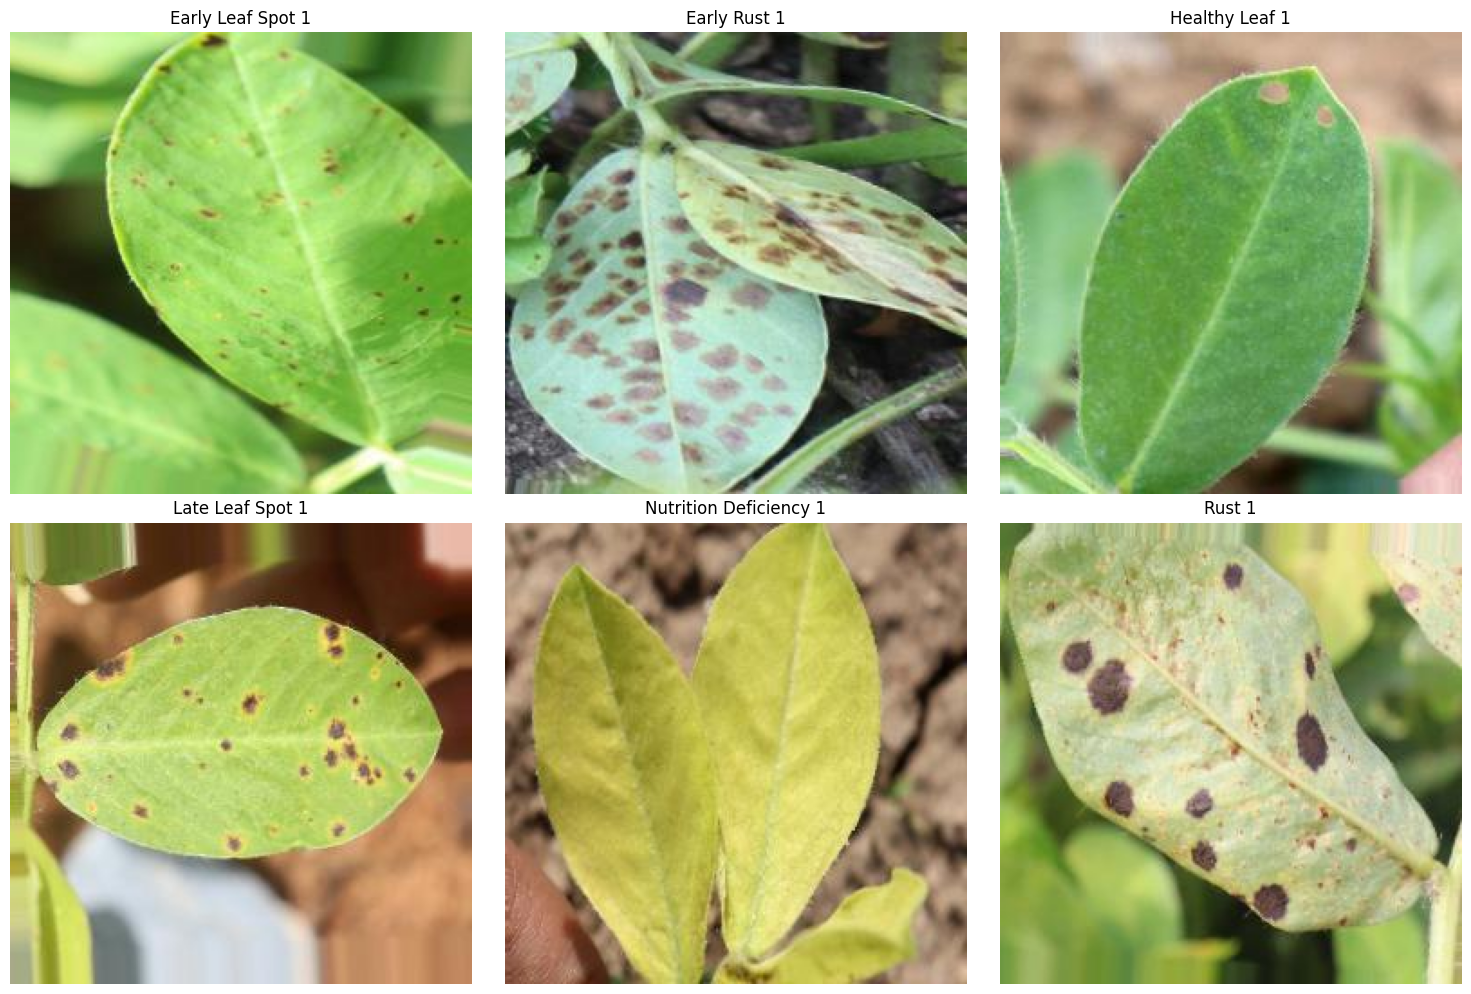

In [11]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

train_dir = os.path.join(dataset_path, "train")

class_names = sorted([
    name for name in os.listdir(train_dir)
    if os.path.isdir(os.path.join(train_dir, name))
])

plt.figure(figsize=(15, 10))
random.seed(42)

for i, class_name in enumerate(class_names):
    class_path = os.path.join(train_dir, class_name)
    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    image_name = random.choice(images)
    image_path = os.path.join(class_path, image_name)

    img = Image.open(image_path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(class_name.replace("_", " ").title())
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_dir = "/content/groundnut_dataset/Groundnut_Leaf_dataset/train"
test_dir = "/content/groundnut_dataset/Groundnut_Leaf_dataset/test"

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True,
    seed=SEED
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Found 7910 files belonging to 6 classes.
Found 2451 files belonging to 6 classes.
Classes: ['early_leaf_spot_1', 'early_rust_1', 'healthy_leaf_1', 'late_leaf_spot_1', 'nutrition_deficiency_1', 'rust_1']
Number of classes: 6


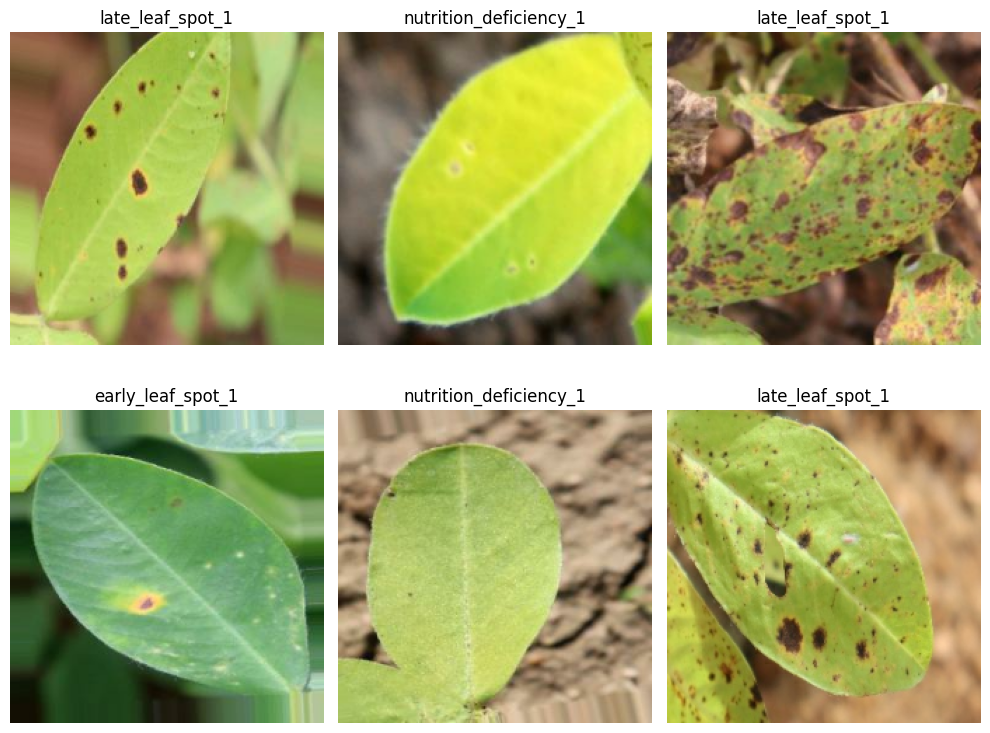

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Number of classes in our dataset
num_classes = len(class_names)

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers
base_model.trainable = False

# Build our classification model
inputs = layers.Input(shape=(224, 224, 3))

# Apply MobileNetV2 preprocessing
x = tf.keras.applications.mobilenet_v2.preprocess_input(inputs)

# Extract image features
x = base_model(x, training=False)

# Classification layers
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)

model = models.Model(inputs, outputs)

# Compile model
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display model architecture
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_ds.prefetch(AUTOTUNE)
test_data = test_ds.prefetch(AUTOTUNE)

history = model.fit(
    train_data,
    epochs=5,
    validation_data=test_data
)

Epoch 1/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 34s 86ms/step - accuracy: 0.7660 - loss: 0.6422 - val_accuracy: 0.8976 - val_loss: 0.3220
Epoch 2/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.8936 - loss: 0.3058 - val_accuracy: 0.9098 - val_loss: 0.2858
Epoch 3/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.9190 - loss: 0.2378 - val_accuracy: 0.9241 - val_loss: 0.2302
Epoch 4/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.9291 - loss: 0.2036 - val_accuracy: 0.9217 - val_loss: 0.2271
Epoch 5/5
248/248 ━━━━━━━━━━━━━━━━━━━━ 10s 38ms/step - accuracy: 0.9363 - loss: 0.1810 - val_accuracy: 0.9310 - val_loss: 0.1970


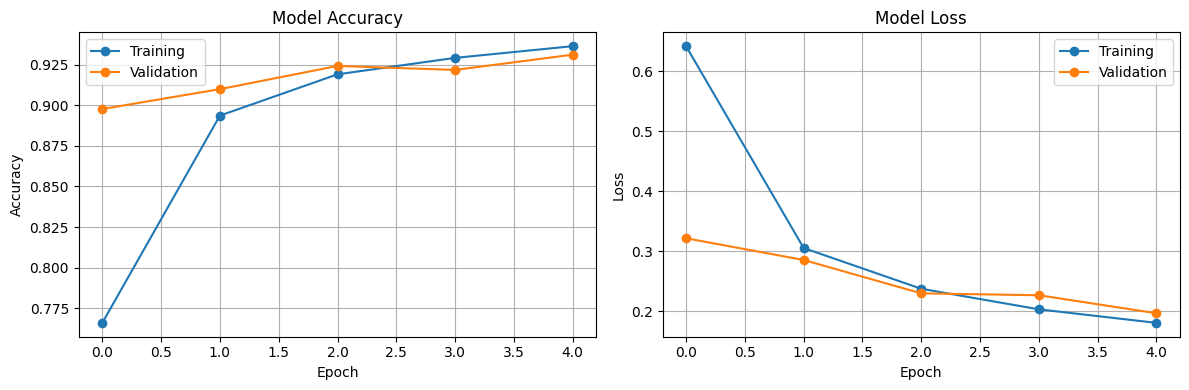

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], marker="o", label="Training")
plt.plot(history.history["val_accuracy"], marker="o", label="Validation")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], marker="o", label="Training")
plt.plot(history.history["val_loss"], marker="o", label="Validation")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

77/77 ━━━━━━━━━━━━━━━━━━━━ 11s 73ms/step
                        precision    recall  f1-score   support

     early_leaf_spot_1       0.95      0.85      0.90       409
          early_rust_1       1.00      0.99      1.00       409
        healthy_leaf_1       0.79      0.84      0.82       409
      late_leaf_spot_1       0.99      0.99      0.99       405
nutrition_deficiency_1       0.87      0.92      0.89       410
                rust_1       1.00      1.00      1.00       409

              accuracy                           0.93      2451
             macro avg       0.93      0.93      0.93      2451
          weighted avg       0.93      0.93      0.93      2451

Macro F1-score: 0.9316


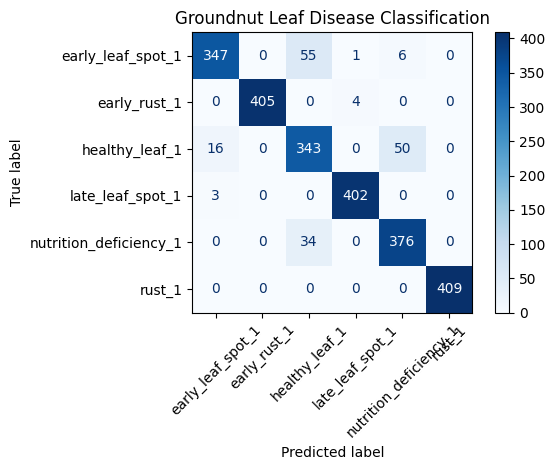

In [17]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt

# Predict test-set classes
y_true = np.concatenate([y.numpy() for x, y in test_ds])
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Classification report
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

print("Macro F1-score:",
      round(f1_score(y_true, y_pred, average="macro"), 4))

# Confusion matrix
cm = confusion_matrix(
    y_true, y_pred, labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Groundnut Leaf Disease Classification")
plt.tight_layout()
plt.show()

In [18]:
# Unfreeze the pretrained model for fine-tuning
base_model.trainable = True

# Freeze most layers and train only the last 30 layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Compile with a very small learning rate
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Fine-tuning setup complete!")
print("Trainable parameters:",
      sum(tf.keras.backend.count_params(w)
          for w in model.trainable_weights))

Fine-tuning setup complete!
Trainable parameters: 1534086


In [19]:
history_fine = model.fit(
    train_data,
    epochs=3,
    validation_data=test_data
)

Epoch 1/3
248/248 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.8578 - loss: 0.3939 - val_accuracy: 0.9102 - val_loss: 0.2248
Epoch 2/3
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 46ms/step - accuracy: 0.9216 - loss: 0.2193 - val_accuracy: 0.9372 - val_loss: 0.2004
Epoch 3/3
248/248 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.9458 - loss: 0.1515 - val_accuracy: 0.9514 - val_loss: 0.1626


77/77 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step
Test accuracy: 0.9514
Macro F1-score: 0.9518

Classification Report:

                        precision    recall  f1-score   support

     early_leaf_spot_1       0.93      0.82      0.87       409
          early_rust_1       0.99      0.99      0.99       409
        healthy_leaf_1       0.82      0.94      0.88       409
      late_leaf_spot_1       0.99      1.00      0.99       405
nutrition_deficiency_1       1.00      0.97      0.98       410
                rust_1       1.00      0.99      1.00       409

              accuracy                           0.95      2451
             macro avg       0.95      0.95      0.95      2451
          weighted avg       0.95      0.95      0.95      2451



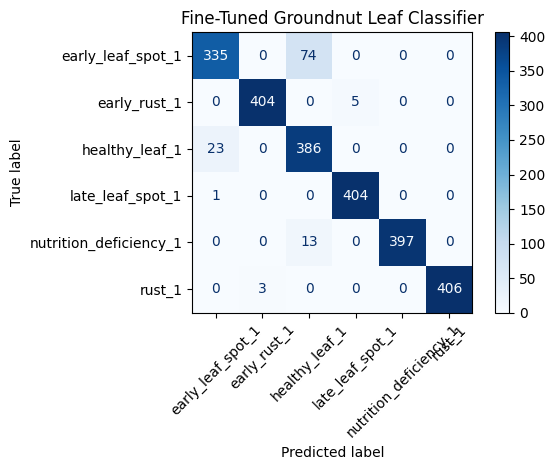

In [20]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)
import numpy as np
import matplotlib.pyplot as plt

# Get actual labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

# Predict using the fine-tuned model
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Calculate metrics
print("Test accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("Macro F1-score:", round(
    f1_score(y_true, y_pred, average="macro"), 4
))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

# Plot confusion matrix
cm = confusion_matrix(
    y_true, y_pred,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)
disp.plot(xticks_rotation=45, cmap="Blues")
plt.title("Fine-Tuned Groundnut Leaf Classifier")
plt.tight_layout()
plt.show()

Saving 111.jpg to 111.jpg


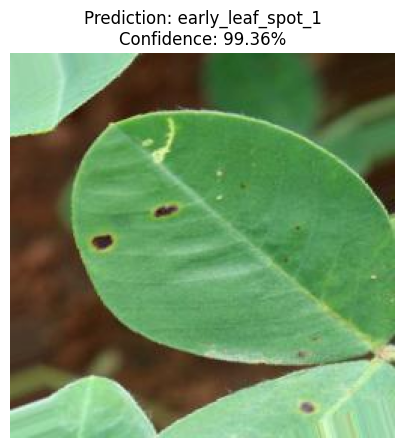

Predicted class: early_leaf_spot_1
Confidence: 99.36%


In [23]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Upload a leaf image
uploaded_image = files.upload()

image_name = next(iter(uploaded_image))

# Load and resize the image
img = Image.open(image_name).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare input
image_array = np.array(img_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Predict
predictions = model.predict(image_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Saving healthy.jpg to healthy.jpg


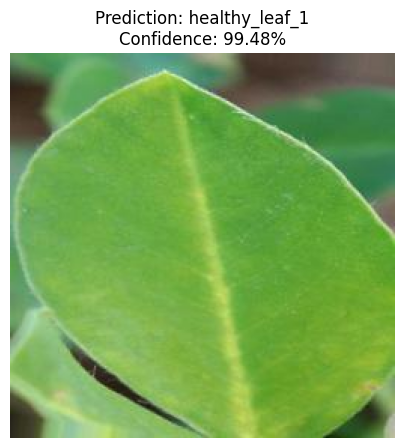

Predicted class: healthy_leaf_1
Confidence: 99.48%


In [24]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Upload a leaf image
uploaded_image = files.upload()

image_name = next(iter(uploaded_image))

# Load and resize the image
img = Image.open(image_name).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare input
image_array = np.array(img_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Predict
predictions = model.predict(image_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

Saving nu di.jpg to nu di.jpg


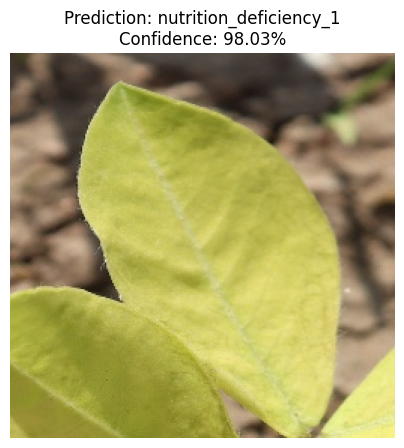

Predicted class: nutrition_deficiency_1
Confidence: 98.03%


In [25]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Upload a leaf image
uploaded_image = files.upload()

image_name = next(iter(uploaded_image))

# Load and resize the image
img = Image.open(image_name).convert("RGB")
img_resized = img.resize((224, 224))

# Prepare input
image_array = np.array(img_resized, dtype=np.float32)
image_array = np.expand_dims(image_array, axis=0)

# Predict
predictions = model.predict(image_array, verbose=0)[0]
predicted_index = np.argmax(predictions)
predicted_class = class_names[predicted_index]
confidence = predictions[predicted_index] * 100

# Display result
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.title(
    f"Prediction: {predicted_class}\n"
    f"Confidence: {confidence:.2f}%"
)
plt.show()

print("Predicted class:", predicted_class)
print(f"Confidence: {confidence:.2f}%")

In [26]:
from google.colab import drive
import os

drive.mount('/content/drive')

save_dir = "/content/drive/MyDrive/Groundnut_Project"
os.makedirs(save_dir, exist_ok=True)

model_path = os.path.join(save_dir, "groundnut_leaf_model.keras")

model.save(model_path)

print("Model saved successfully!")
print("Location:", model_path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model saved successfully!
Location: /content/drive/MyDrive/Groundnut_Project/groundnut_leaf_model.keras


In [27]:
import json
import os

class_names_path = os.path.join(
    "/content/drive/MyDrive/Groundnut_Project",
    "class_names.json"
)

with open(class_names_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")
print(class_names)

Class names saved successfully!
['early_leaf_spot_1', 'early_rust_1', 'healthy_leaf_1', 'late_leaf_spot_1', 'nutrition_deficiency_1', 'rust_1']


In [28]:
import tensorflow as tf
import os

model_path = (
    "/content/drive/MyDrive/Groundnut_Project/"
    "groundnut_leaf_model.keras"
)

loaded_model = tf.keras.models.load_model(model_path)

print("Saved model loaded successfully!")
print("Output classes:", loaded_model.output_shape[-1])

Saved model loaded successfully!
Output classes: 6


In [29]:
import json
import os

class_names_path = os.path.join(
    "/content/drive/MyDrive/Groundnut_Project",
    "class_names.json"
)

with open(class_names_path, "w") as f:
    json.dump(class_names, f, indent=4)

print("Class names saved successfully!")
print(class_names)

Class names saved successfully!
['early_leaf_spot_1', 'early_rust_1', 'healthy_leaf_1', 'late_leaf_spot_1', 'nutrition_deficiency_1', 'rust_1']
